# Base student model training

In [1]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F
import json

In [2]:
seeds = [42, 43, 44, 45, 46]
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

aug_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

In [3]:
torch.manual_seed(42)
np.random.seed(42)

data_dir = '/kaggle/input/datasets/nirmalsankalana/potato-leaf-disease-dataset'
num_classes = 7
batch_size = 32
num_epochs = 50
lr = 1e-3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
train_full_dataset = datasets.ImageFolder(data_dir, transform=aug_transforms)
val_full_dataset = datasets.ImageFolder(data_dir, transform=data_transforms)
class_names = train_full_dataset.classes
targets = train_full_dataset.targets

train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.2, random_state=42, stratify=targets
)

print(f"Training images: {len(train_idx)} | Hold-out test images: {len(val_idx)}")

Training images: 2460 | Hold-out test images: 616


In [5]:
class dsconv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size=kernel_size, 
                                   padding=padding, groups=in_channels, bias=False)
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.act = nn.ReLU(inplace=True)
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias = False)
        self.bn2 = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        x = self.depthwise(x)
        x = self.bn1(x)
        x = self.act(x)
        x = self.pointwise(x)
        x = self.bn2(x)
        return x

class CBAM(nn.Module):
    #Channel attention (avg + max, shared MLP), spatial attention (7x7 conv).
    def __init__(self, channels, reduction=8, kernel_size=7):
        super().__init__()
        reduced = max(4, channels // reduction)
        self.mlp = nn.Sequential(
            nn.Linear(channels, reduced, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(reduced, channels, bias=False)
        )
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        b, c, _, _ = x.size()
        keep = x
        avg = self.mlp(x.mean(dim=(2, 3)))
        mx = self.mlp(x.amax(dim=(2, 3)))
        x = x * torch.sigmoid(avg + mx).view(b, c, 1, 1)                  
        s = torch.cat([x.mean(dim=1, keepdim=True),
                       x.amax(dim=1, keepdim=True)], dim=1)               
        return x * torch.sigmoid(self.spatial(s)) + keep                      

class StdConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Conv2d(in_c, out_c, 3, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_c)
    def forward(self, x):
        return self.bn(self.conv(x))

class CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.conv1 = StdConv(3, 16)
        self.relu1 = nn.ReLU()
        self.attention1 = CBAM(16)
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = dsconv(16, 32)
        self.relu2 = nn.ReLU()
        self.attention2 = CBAM(32)
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = dsconv(32, 64)
        self.relu3 = nn.ReLU()
        self.attention3 = CBAM(64)
        self.pool3 = nn.MaxPool2d(2)

        self.conv4 = dsconv(64, 128)
        self.relu4 = nn.ReLU()
        self.attention4 = CBAM(128)
        self.pool4 = nn.MaxPool2d(2)

        self.conv5 = dsconv(128, 256)
        self.relu5 = nn.ReLU()
        self.attention5 = CBAM(256)
        self.pool5 = nn.MaxPool2d(2)

        self.conv6 = dsconv(256, 512)
        self.relu6 = nn.ReLU()
       

        self.classifier = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(64 + 128 + 256 + 512, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x, return_feat=False):
        x = self.pool1(self.attention1(self.relu1(self.conv1(x))))
        x = self.pool2(self.attention2(self.relu2(self.conv2(x))))
        f3 = self.pool3(self.attention3(self.relu3(self.conv3(x))))
        f4 = self.pool4(self.attention4(self.relu4(self.conv4(f3))))  
        f5 = self.pool5(self.attention5(self.relu5(self.conv5(f4))))   
        f6 = self.relu6(self.conv6(f5))                                

        fused  = torch.cat([f.mean(dim=(2, 3)) for f in (f3, f4, f5, f6)], dim=1)
        logits = self.classifier(fused)
        return (logits, [f3, f4, f6]) if return_feat else logits

def make_sampler(labels, num_classes=7):

    class_sample_count = np.bincount(labels, minlength=num_classes)
    weights = 1.0 / np.sqrt(class_sample_count)
    samples_weight = [weights[label] for label in labels]
    return WeightedRandomSampler(weights=samples_weight, num_samples=len(samples_weight), replacement=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn = CNN(7).to(device)
cnn_params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(f"Parameters in CNN- {cnn_params:,}\n")

Parameters in CNN- 266,833



In [6]:
results = {}

train_dataset = Subset(train_full_dataset, train_idx)
test_dataset = Subset(val_full_dataset, val_idx)
train_labels = [targets[i] for i in train_idx]

for seed in seeds:
    torch.manual_seed(seed)
    sampler = make_sampler(train_labels, num_classes)
    
    dataloaders = {
        'Train': DataLoader(train_dataset, batch_size=batch_size, sampler=sampler),
        'Valid': DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    }
    
    cnn = CNN(num_classes).to(device)
    
    optimizer = torch.optim.AdamW(cnn.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    
    best_val_acc = 0.0
    train_losses = []
    val_accs = []
    cnn_path = f'best_base_student_{seed}.pth'
    
    
    for epoch in range(num_epochs):
        cnn.train()
        total_loss, correct, total = 0, 0, 0
    
        for inputs, labels in dataloaders['Train']:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
    
            student_logits = cnn(inputs)
    
            loss = F.cross_entropy(student_logits, labels)
            loss.backward()
            optimizer.step()
    
            total_loss += loss.item() * inputs.size(0)
            preds = student_logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
        scheduler.step()
        train_loss = total_loss / total
        train_acc = correct / total
    
        cnn.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for val_inputs, val_labels in dataloaders['Valid']:
                val_inputs, val_labels = val_inputs.to(device), val_labels.to(device)
                val_preds = cnn(val_inputs).argmax(dim=1)
                val_correct += (val_preds == val_labels).sum().item()
                val_total += val_labels.size(0)
    
        val_acc = val_correct / val_total

        train_losses.append(train_loss)
        val_accs.append(val_acc)
    
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(cnn.state_dict(), cnn_path)
           
        if (epoch + 1) % 10 == 0:
            print(f"seed {seed} | epoch {epoch + 1}: train_loss = {train_loss:.4f} | train_acc = {train_acc:.4f} | holdout_acc = {val_acc:.4f}")
    results[seed] = dict(best=best_val_acc, last=val_acc, train_loss=train_losses, val_acc=val_accs)
    print(f"seed {seed}: best {best_val_acc:.4f} | last {val_acc:.4f}\n")

seed 42 | epoch 10: train_loss = 1.0809 | train_acc = 0.5776 | holdout_acc = 0.5925
seed 42 | epoch 20: train_loss = 0.8310 | train_acc = 0.6711 | holdout_acc = 0.6331
seed 42 | epoch 30: train_loss = 0.6397 | train_acc = 0.7630 | holdout_acc = 0.6948
seed 42 | epoch 40: train_loss = 0.5474 | train_acc = 0.7976 | holdout_acc = 0.7370
seed 42 | epoch 50: train_loss = 0.5446 | train_acc = 0.7976 | holdout_acc = 0.7451
seed 42: best 0.7565 | last 0.7451

seed 43 | epoch 10: train_loss = 1.0477 | train_acc = 0.5817 | holdout_acc = 0.6185
seed 43 | epoch 20: train_loss = 0.7580 | train_acc = 0.7220 | holdout_acc = 0.6769
seed 43 | epoch 30: train_loss = 0.6191 | train_acc = 0.7659 | holdout_acc = 0.7192
seed 43 | epoch 40: train_loss = 0.4909 | train_acc = 0.8199 | holdout_acc = 0.7565
seed 43 | epoch 50: train_loss = 0.4921 | train_acc = 0.8175 | holdout_acc = 0.7695
seed 43: best 0.7744 | last 0.7695

seed 44 | epoch 10: train_loss = 1.0157 | train_acc = 0.6203 | holdout_acc = 0.5779
seed


Classification Report (616 Hold-Out Images):
              precision    recall  f1-score   support

    Bacteria     0.8560    0.9386    0.8954       114
       Fungi     0.7152    0.7533    0.7338       150
     Healthy     0.6471    0.5500    0.5946        40
    Nematode     0.8000    0.8571    0.8276        14
        Pest     0.6907    0.5492    0.6119       122
 Phytopthora     0.8727    0.6957    0.7742        69
       Virus     0.7348    0.9065    0.8117       107

    accuracy                         0.7565       616
   macro avg     0.7595    0.7501    0.7499       616
weighted avg     0.7550    0.7565    0.7507       616



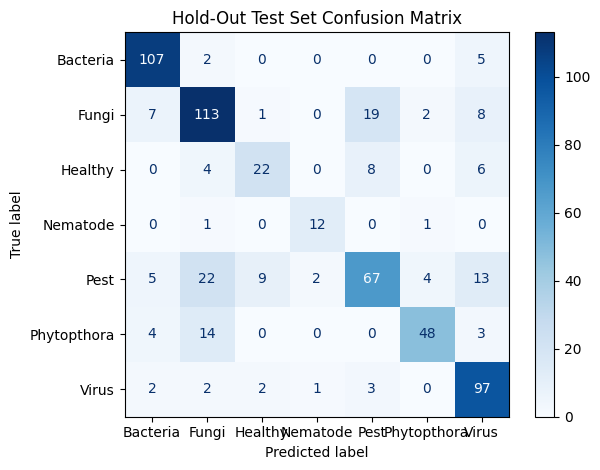

In [7]:
cnn_path = 'best_base_student_42.pth'

cnn.load_state_dict(torch.load(cnn_path, map_location=device, weights_only=True))
cnn.eval()

all_y_true, all_y_pred = [], []
with torch.no_grad():
    for val_inputs, val_labels in dataloaders['Valid']:
        val_inputs = val_inputs.to(device)
        val_preds = cnn(val_inputs).argmax(dim=1)
        all_y_true.extend(val_labels.tolist())
        all_y_pred.extend(val_preds.cpu().tolist())

print("\nClassification Report (616 Hold-Out Images):")
print(classification_report(all_y_true, all_y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(all_y_true, all_y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Hold-Out Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig("base_student_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
with open("base_student_results.json", "w") as f:
    json.dump(results, f, indent=2)

best = np.array([results[s]["best"] for s in seeds]) * 100
last = np.array([results[s]["last"] for s in seeds]) * 100

for s, b, l in zip(seeds, best, last):
    print(f"seed {s} | best: {b:.2f}% | last: {l:.2f}%")
print(f"mean   | best: {best.mean():.2f} +/- {best.std(ddof=1):.2f}% | last: {last.mean():.2f} +/- {last.std(ddof=1):.2f}%")

seed 42 | best: 75.65% | last: 74.51%
seed 43 | best: 77.44% | last: 76.95%
seed 44 | best: 76.30% | last: 75.97%
seed 45 | best: 77.44% | last: 75.81%
seed 46 | best: 76.79% | last: 75.97%
mean   | best: 76.72 +/- 0.77% | last: 75.84 +/- 0.87%


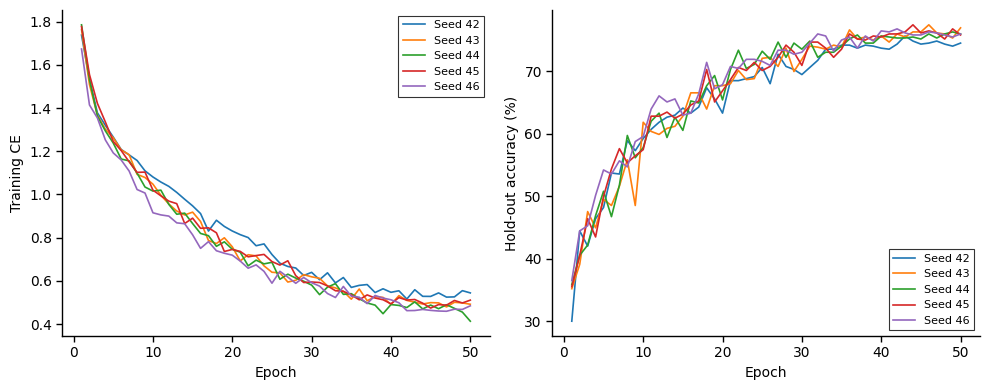

In [9]:
epochs = np.arange(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

for s in seeds:
    ax1.plot(epochs, results[s]["train_loss"], lw=1.2, label=f"Seed {s}")
    ax2.plot(epochs, np.array(results[s]["val_acc"]) * 100, lw=1.2, label=f"Seed {s}")

ax1.set_ylabel("Training CE")
ax2.set_ylabel("Hold-out accuracy (%)")

for ax, loc in ((ax1, "upper right"), (ax2, "lower right")):
    ax.set_xlabel("Epoch")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.0)
    ax.spines["bottom"].set_linewidth(1.0)
    ax.tick_params(direction="out", which="major", length=4, width=1.0)
    ax.minorticks_off()
    leg = ax.legend(loc=loc, frameon=True, fancybox=False, edgecolor="black", fontsize=8)
    leg.get_frame().set_linewidth(0.8)

fig.tight_layout()
fig.savefig("base_student.png", dpi=300, bbox_inches="tight")
plt.show()